(256, 4096)


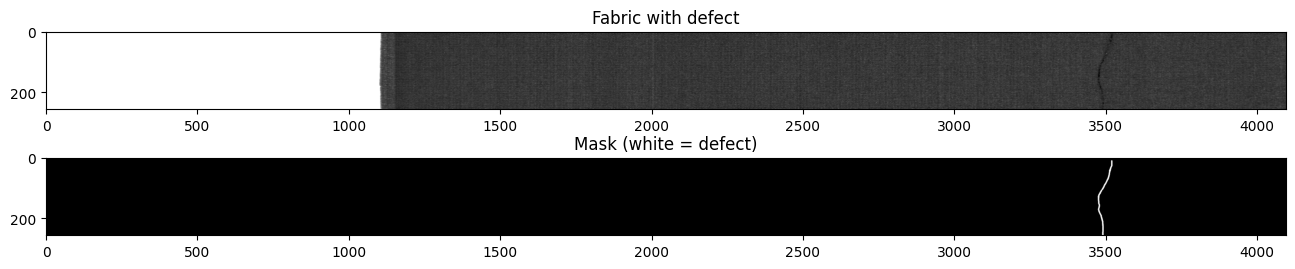

In [1]:
import cv2
import matplotlib.pyplot as plt

defect = cv2.imread("data/Defect_images/0001_002_00.png", cv2.IMREAD_GRAYSCALE)
mask   = cv2.imread("data/Mask_images/0001_002_00_mask.png", cv2.IMREAD_GRAYSCALE)

print(defect.shape)

fig, ax = plt.subplots(2, 1, figsize=(16, 3))
ax[0].imshow(defect, cmap="gray"); ax[0].set_title("Fabric with defect")
ax[1].imshow(mask, cmap="gray");   ax[1].set_title("Mask (white = defect)")
plt.show()

In [3]:
import os, glob
import numpy as np

TILE = 256
tiles, labels = [], []

def cut_image(img, mask=None):
    for x in range(0, img.shape[1], TILE):
        tile = img[:, x:x+TILE]
        if tile.shape != (TILE, TILE):   # leftover scrap or wrong height, skip
            continue
        if tile.mean() > 240:            # almost all white = no fabric, skip
            continue
        if mask is not None:
            label = 1 if mask[:, x:x+TILE].max() > 0 else 0
        else:
            label = 0
        tiles.append(tile)
        labels.append(label)

# defect images (with masks)
for path in glob.glob("data/Defect_images/*.png"):
    name = os.path.basename(path).replace(".png", "_mask.png")
    mask = cv2.imread(f"data/Mask_images/{name}", cv2.IMREAD_GRAYSCALE)
    img  = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is not None:
        cut_image(img, mask)

# defect-free images (inside sub-folders)
for path in glob.glob("data/NODefect_images/*/*.png"):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    cut_image(img)

tiles = np.array(tiles)
labels = np.array(labels)
print("Tiles:", tiles.shape)
print("Defect tiles:", labels.sum(), "| OK tiles:", (labels == 0).sum())

Tiles: (3552, 256, 256)
Defect tiles: 183 | OK tiles: 3369


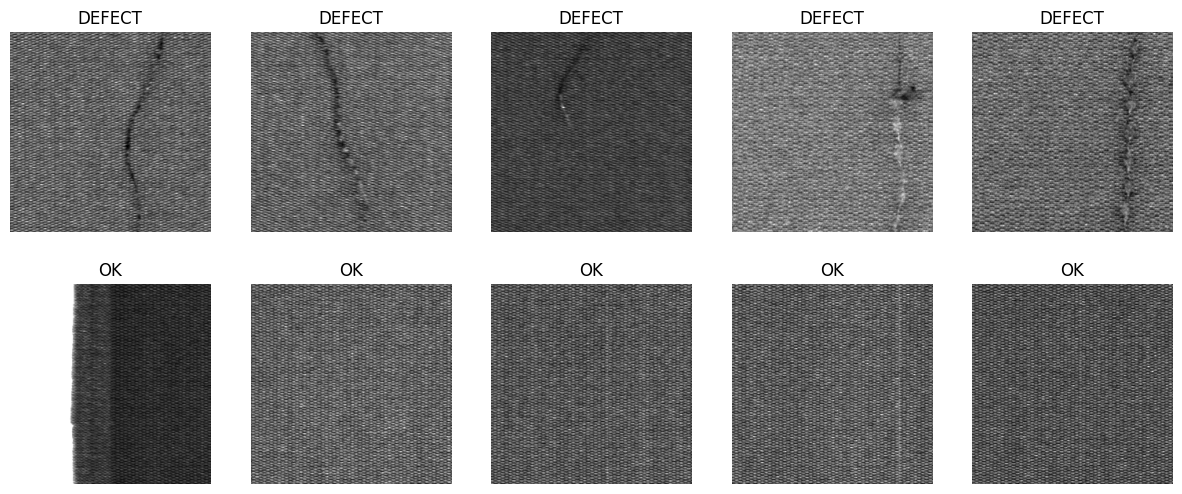

In [4]:
defect_idx = np.where(labels == 1)[0][:5]
ok_idx     = np.where(labels == 0)[0][:5]

fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for i, idx in enumerate(defect_idx):
    ax[0, i].imshow(tiles[idx], cmap="gray"); ax[0, i].set_title("DEFECT"); ax[0, i].axis("off")
for i, idx in enumerate(ok_idx):
    ax[1, i].imshow(tiles[idx], cmap="gray"); ax[1, i].set_title("OK"); ax[1, i].axis("off")
plt.show()

In [5]:
TILE = 256
tiles, labels, groups = [], [], []      # groups = which photo each tile came from

def cut_image(img, photo_id, mask=None):
    for x in range(0, img.shape[1], TILE):
        tile = img[:, x:x+TILE]
        if tile.shape != (TILE, TILE):
            continue
        if tile.mean() > 240:
            continue
        label = 1 if (mask is not None and mask[:, x:x+TILE].max() > 0) else 0
        tiles.append(tile)
        labels.append(label)
        groups.append(photo_id)

for path in glob.glob("data/Defect_images/*.png"):
    name = os.path.basename(path).replace(".png", "_mask.png")
    mask = cv2.imread(f"data/Mask_images/{name}", cv2.IMREAD_GRAYSCALE)
    img  = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is not None:
        cut_image(img, path, mask)

for path in glob.glob("data/NODefect_images/*/*.png"):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    cut_image(img, path)

tiles, labels, groups = np.array(tiles), np.array(labels), np.array(groups)
print(tiles.shape, labels.sum())

(3552, 256, 256) 183


In [6]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(tiles, labels, groups))

print("Train tiles:", len(train_idx), "| defects:", labels[train_idx].sum())
print("Test tiles: ", len(test_idx),  "| defects:", labels[test_idx].sum())
print("Shared photos:", len(set(groups[train_idx]) & set(groups[test_idx])))

Train tiles: 2848 | defects: 140
Test tiles:  704 | defects: 43
Shared photos: 0


In [7]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

test_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class FabricDataset(Dataset):
    def __init__(self, idx, tf):
        self.idx, self.tf = idx, tf
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(tiles[j]), labels[j]

train_loader = DataLoader(FabricDataset(train_idx, train_tf), batch_size=32, shuffle=True)
test_loader  = DataLoader(FabricDataset(test_idx,  test_tf),  batch_size=32, shuffle=False)

x, y = next(iter(train_loader))
print(x.shape, y[:10])

torch.Size([32, 3, 224, 224]) tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [8]:
import torch.nn as nn
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():
    p.requires_grad = False          # freeze: don't change what ResNet already knows

model.fc = nn.Linear(model.fc.in_features, 2)   # new last layer: 2 outputs (OK, defect)

# class weights: defects are rare (~5%), so mistakes on them count more
n_ok, n_def = (labels[train_idx] == 0).sum(), (labels[train_idx] == 1).sum()
weights = torch.tensor([1.0, n_ok / n_def], dtype=torch.float32)
loss_fn = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
print("Defect weight:", round(weights[1].item(), 1))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\jamal/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Defect weight: 19.3


In [9]:
for epoch in range(5):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        optimizer.zero_grad()            # clear old corrections
        out = model(x)                   # 1. guess
        loss = loss_fn(out, y)           # 2. measure how wrong
        loss.backward()                  # 3. work out how to fix it
        optimizer.step()                 # 4. apply the fix
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: loss {total_loss/len(train_loader):.3f}")

Epoch 1: loss 0.664
Epoch 2: loss 0.597
Epoch 3: loss 0.635
Epoch 4: loss 0.572
Epoch 5: loss 0.571


In [10]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

model.eval()
all_probs, all_y = [], []

with torch.no_grad():
    for x, y in test_loader:
        probs = torch.softmax(model(x), dim=1)[:, 1]   # chance of "defect"
        all_probs.extend(probs.numpy())
        all_y.extend(y.numpy())

all_probs, all_y = np.array(all_probs), np.array(all_y)
preds = (all_probs >= 0.5).astype(int)

print(confusion_matrix(all_y, preds))
print(classification_report(all_y, preds, digits=3))
print("ROC-AUC:", round(roc_auc_score(all_y, all_probs), 3))

[[445 216]
 [ 20  23]]
              precision    recall  f1-score   support

           0      0.957     0.673     0.790       661
           1      0.096     0.535     0.163        43

    accuracy                          0.665       704
   macro avg      0.527     0.604     0.477       704
weighted avg      0.904     0.665     0.752       704

ROC-AUC: 0.64


In [11]:
# un-freeze the deeper layers so they can learn fabric textures
for p in model.layer3.parameters():
    p.requires_grad = True
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer3.parameters(), "lr": 1e-4},   # gentle changes
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},   # last layer learns faster
])

for epoch in range(8):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: loss {total_loss/len(train_loader):.3f}")

Epoch 1: loss 0.573
Epoch 2: loss 0.340
Epoch 3: loss 0.307
Epoch 4: loss 0.277
Epoch 5: loss 0.267
Epoch 6: loss 0.248
Epoch 7: loss 0.173
Epoch 8: loss 0.157


In [12]:
model.eval()
all_probs, all_y = [], []

with torch.no_grad():
    for x, y in test_loader:
        probs = torch.softmax(model(x), dim=1)[:, 1]
        all_probs.extend(probs.numpy())
        all_y.extend(y.numpy())

all_probs, all_y = np.array(all_probs), np.array(all_y)
preds = (all_probs >= 0.5).astype(int)

print(confusion_matrix(all_y, preds))
print(classification_report(all_y, preds, digits=3))
print("ROC-AUC:", round(roc_auc_score(all_y, all_probs), 3))

[[655   6]
 [ 16  27]]
              precision    recall  f1-score   support

           0      0.976     0.991     0.983       661
           1      0.818     0.628     0.711        43

    accuracy                          0.969       704
   macro avg      0.897     0.809     0.847       704
weighted avg      0.967     0.969     0.967       704

ROC-AUC: 0.962


In [13]:
from sklearn.metrics import precision_score, recall_score

for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    p = (all_probs >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(all_y, p):.3f}  "
          f"recall {recall_score(all_y, p):.3f}  flagged {p.sum()}")

threshold 0.5: precision 0.818  recall 0.628  flagged 33
threshold 0.4: precision 0.778  recall 0.651  flagged 36
threshold 0.3: precision 0.667  recall 0.744  flagged 48
threshold 0.2: precision 0.567  recall 0.791  flagged 60
threshold 0.1: precision 0.412  recall 0.814  flagged 85
threshold 0.05: precision 0.304  recall 0.884  flagged 125


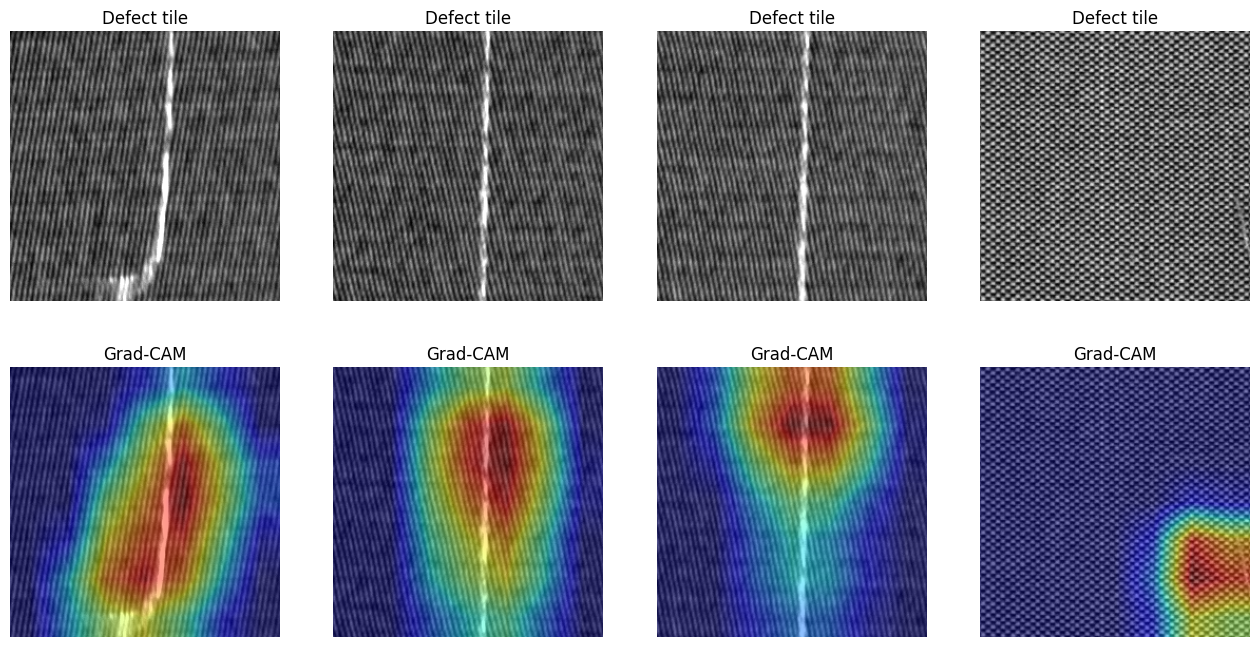

In [14]:
model.eval()
feats = {}
model.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))
model.layer4.register_full_backward_hook(lambda m, gi, go: feats.__setitem__("g", go[0]))

def gradcam(j):
    x = test_tf(tiles[j]).unsqueeze(0).requires_grad_(True)
    out = model(x); model.zero_grad(); out[0, 1].backward()
    w = feats["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats["a"]).sum(1)).squeeze().detach().numpy()
    return cv2.resize(cam / (cam.max() + 1e-8), (256, 256))

hits = [test_idx[k] for k in np.where((all_y == 1) & (all_probs >= 0.2))[0][:4]]
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for i, j in enumerate(hits):
    ax[0, i].imshow(tiles[j], cmap="gray"); ax[0, i].set_title("Defect tile"); ax[0, i].axis("off")
    ax[1, i].imshow(tiles[j], cmap="gray"); ax[1, i].imshow(gradcam(j), cmap="jet", alpha=0.45)
    ax[1, i].set_title("Grad-CAM"); ax[1, i].axis("off")
plt.savefig("gradcam.png", dpi=120, bbox_inches="tight"); plt.show()

In [15]:
torch.save(model.state_dict(), "fabric_resnet18.pt")